# Lab 01 — Exploratory Data Analysis

*Machine Learning and Data Mining — Claudio Sartori, University of Bologna*

Part A is adapted from the *Python Data Science Handbook* by Jake VanderPlas
([book](http://shop.oreilly.com/product/0636920034919.do), [GitHub](https://github.com/jakevdp/PythonDataScienceHandbook));
text released under [CC-BY-NC-ND](https://creativecommons.org/licenses/by-nc-nd/3.0/us/legalcode), code under the [MIT license](https://opensource.org/licenses/MIT).

## Goal of this lab

Apply the **EDA checklist** of Lecture 6 in code, with the tools of Lecture 7.

| # | Checklist item | Part A — Iris | Part B — NordicMart |
|---|---|---|---|
| 1 | Kind of data set; type of every column; identifiers out | A1 | B1 |
| 2 | Summaries and one plot per variable | A2 | B2 |
| 3 | Missing values: how many, and why | A3 | B3 |
| 4 | Codes, defaults, impossible values, outliers, duplicates | A3 | B3 |
| 5 | The target: balance | A4 | B4 |
| 6 | Each feature × target; correlations; confounders | A5 | B5 |
| 7 | Write down findings → preparation actions | A6 | B6 |

- **Part A (≈ 40 min)** — the Iris data set: small and clean, to learn the calls.
- **Part B (≈ 60 min)** — the NordicMart customer table seen in the lecture: real-looking problems, to practice the judgement.
- Exercises marked ★ are optional: do them if you have time, or at home.

### How to work (notebook good practices)

- Write code in the empty cells; write **answers and findings in markdown cells**, not in comments.
- Never modify the raw data: the raw tables are loaded once and **not changed**; every fix goes into a working copy.
- Before closing: **Kernel → Restart & Run All**. The notebook must run from top to bottom without errors.

## Setup

All imports, paths and constants in one place. Adjust `DATA_DIR` if your data folder is somewhere else.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

DATA_DIR = Path("../../data")                      # relative path: works on any machine
IRIS_FILE = DATA_DIR / "iris.csv"
NORDICMART_FILE = DATA_DIR / "nordicmart_customers.csv"
SEED = 42                                          # fixed seed: same "random" results at every run

pd.set_option("display.precision", 2)
plt.rcParams["figure.figsize"] = (8, 4)

print("pandas", pd.__version__, "| numpy", np.__version__, "| seaborn", sns.__version__)

pandas 3.0.5 | numpy 2.5.3 | seaborn 0.13.2


# Part A — Iris

The [Iris data set](https://en.wikipedia.org/wiki/Iris_flower_data_set), analysed by Ronald Fisher in 1936:
measurements of 150 iris flowers of three species.
Your data folder contains two files, `iris.csv` and `iris.names`.

## A1. Kind of data set and type of every column

### Look at the raw file before loading it

Open `iris.csv` and `iris.names` as text (a text editor, or the cell below) and answer:

1. is it a `csv` file or something else?
1. what is the *separator* character (`,`, `;`, `\t`, ...)?
1. is there a *header*, i.e. a first row with the column names?
1. if there is no header, where can you find reasonable names? (for UCI data sets: the `.names` file)
1. is the data set supervised? which column is the *target*?

In [2]:
# the first lines of the file, as plain text
with open(IRIS_FILE) as f:
    for _ in range(5):
        print(f.readline(), end="")

5.1,3.5,1.4,0.2,Iris-setosa
4.9,3.0,1.4,0.2,Iris-setosa
4.7,3.2,1.3,0.2,Iris-setosa
4.6,3.1,1.5,0.2,Iris-setosa
5.0,3.6,1.4,0.2,Iris-setosa


**Answer.** A `csv` file, comma-separated, **no header**: the first row is already data.
The column names are in `iris.names`: sepal length, sepal width, petal length, petal width (cm) and class.
It is supervised: the target is the **class** (the species).

### Load the data set into a pandas `DataFrame`

- documentation: [`pd.read_csv()`](https://pandas.pydata.org/docs/reference/api/pandas.read_csv.html) — check how to give the column names when there is no header
- name the DataFrame `iris`; it is the raw table and **will not be modified**

In [3]:
names = ["sepal length", "sepal width", "petal length", "petal width", "class"]
iris = pd.read_csv(IRIS_FILE, header=None, names=names)

Show the column names, the number of rows and columns (attribute `shape`) and the type of each column (`dtypes`, or `info()`).
Then store the size of the data set in two variables, `n_samples` and `n_features`:

- each row is a single flower: a *sample*; the number of rows is `n_samples`
- each column that describes the samples is a *feature*; `class` is **not** a feature but the *target*, so `n_features` is the number of columns minus one

Why these two names? They are the standard vocabulary of scikit-learn: from the next labs on, every model expects the features
as a table of shape `(n_samples, n_features)` and the target as a column of length `n_samples`, and you will read these names
in every docstring. Separating features from target (and, in Part B, from identifiers) is the first decision of any analysis.

In [4]:
print(iris.columns.tolist())
print(f"There are {iris.shape[0]} rows and {iris.shape[1]} columns")
n_samples, n_features = iris.shape[0], iris.shape[1] - 1     # 'class' is the target, not a feature
print(f"n_samples = {n_samples}, n_features = {n_features} (+ 1 target column)")
iris.info()

['sepal length', 'sepal width', 'petal length', 'petal width', 'class']
There are 150 rows and 5 columns
n_samples = 150, n_features = 4 (+ 1 target column)
<class 'pandas.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   sepal length  150 non-null    float64
 1   sepal width   150 non-null    float64
 2   petal length  150 non-null    float64
 3   petal width   150 non-null    float64
 4   class         150 non-null    str    
dtypes: float64(4), str(1)
memory usage: 6.0 KB


Show the first rows with `head()`, then a random sample of rows with `sample(5)`.
Run the `sample` cell twice: what happens? Then add `random_state=SEED` and run it twice again.

In [5]:
iris.head()

,sepal length,sepal width,petal length,petal width,class
0,5.1,3.5,1.4,0.2,Iris-setosa
1,4.9,3.0,1.4,0.2,Iris-setosa
2,4.7,3.2,1.3,0.2,Iris-setosa
3,4.6,3.1,1.5,0.2,Iris-setosa
4,5.0,3.6,1.4,0.2,Iris-setosa


In [6]:
iris.sample(5, random_state=SEED)

,sepal length,sepal width,petal length,petal width,class
73,6.1,2.8,4.7,1.2,Iris-versicolor
18,5.7,3.8,1.7,0.3,Iris-setosa
118,7.7,2.6,6.9,2.3,Iris-virginica
78,6.0,2.9,4.5,1.5,Iris-versicolor
76,6.8,2.8,4.8,1.4,Iris-versicolor


**Question.** For every column, give its type on the scale of Lecture 6 (nominal, ordinal, interval, ratio)
and say whether it is discrete or continuous. Is there an identifier to drop?

**Answer.** The four measurements are **ratio**, continuous (a length has a true zero; 4 cm is twice 2 cm).
`class` is **nominal**, discrete, with 3 values: it is the target. There is no identifier column.
Without `random_state` every run of `sample` shows different rows: results that change at every run are not reproducible.

## A2. Summaries and one plot per variable

The `describe()` method gives a short summary of every numeric column.
Look in the [documentation](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.describe.html)
for the parameter that includes the non-numeric columns too.

In [7]:
iris.describe(include="all")

,sepal length,sepal width,petal length,petal width,class
count,150.00,150.00,150.00,150.00,150
unique,NaN,NaN,NaN,NaN,3
top,NaN,NaN,NaN,NaN,Iris-setosa
freq,NaN,NaN,NaN,NaN,50
mean,5.84,3.06,3.76,1.20,NaN
std,0.83,0.44,1.77,0.76,NaN
min,4.30,2.00,1.00,0.10,NaN
25%,5.10,2.80,1.60,0.30,NaN
50%,5.80,3.00,4.35,1.30,NaN
75%,6.40,3.30,5.10,1.80,NaN


**Question.** For which columns are mean and median (50%) close? What does it tell you about the shape of the distribution?

**Answer.** For the sepal measurements mean and median are almost equal: roughly symmetric distributions.
For petal length (mean 3.76, median 4.35) and petal width the mean is *below* the median: the distribution is not symmetric —
the histograms show why: two separate groups.

Draw a histogram of every numeric column with `DataFrame.hist()` (use `figsize` to adjust the size).
Then redraw only `petal length` with 5, 15 and 40 bins: does the story change?

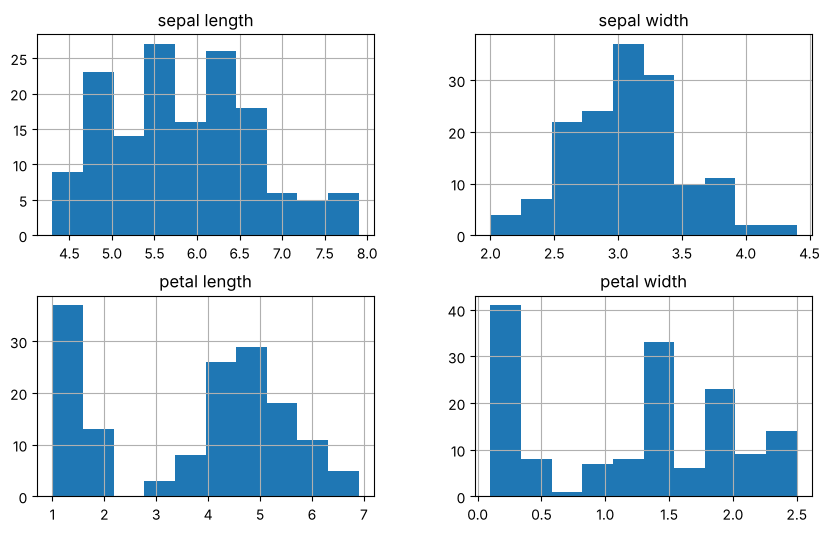

In [8]:
iris.hist(figsize=(10, 6));    # the final `;` suppresses the textual output

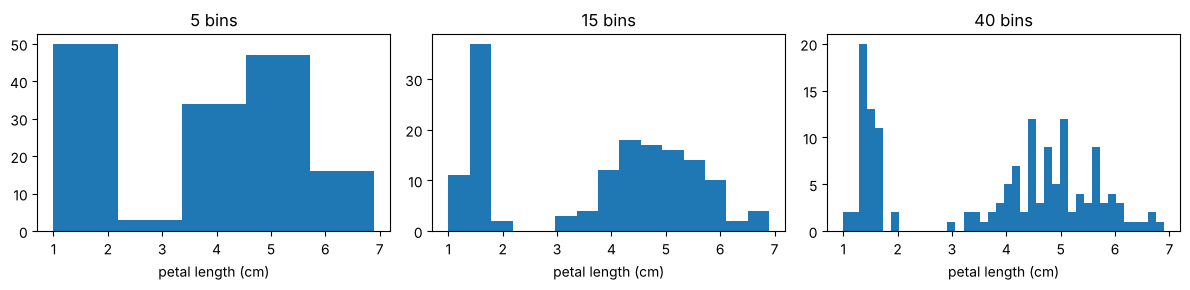

In [9]:
fig, axs = plt.subplots(1, 3, figsize=(12, 3), sharey=False)
for ax, b in zip(axs, [5, 15, 40]):
    ax.hist(iris["petal length"], bins=b)
    ax.set_title(f"{b} bins")
    ax.set_xlabel("petal length (cm)")
plt.tight_layout()

**Answer.** With 5 bins petal length looks like one wide hump; with 15 or 40 bins two separate groups appear
(short petals around 1.5 cm, and the rest). Always try more than one bin width.

Make a box plot of the numeric features with the `boxplot()` method. The four columns share the same unit (cm), so one plot is fine.

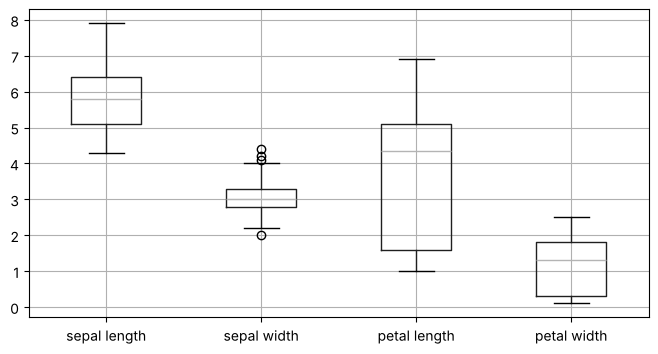

In [10]:
iris.boxplot();

## A3. Data quality: missing values, impossible values, outliers, duplicates

1. Count the missing values per column (`isna().sum()`). Could you already see it from `describe()`?
1. Are there impossible values (zero or negative lengths)?
1. Count the duplicated rows (`duplicated().sum()`) and show them (`iris[iris.duplicated(keep=False)]`).
1. The box plot of `sepal width` shows a few candidate outliers: are they errors?

In [11]:
print(iris.isna().sum())
print("non-positive values:", (iris.select_dtypes("number") <= 0).sum().sum())
print("duplicated rows:", iris.duplicated().sum())
iris[iris.duplicated(keep=False)]

sepal length    0
sepal width     0
petal length    0
petal width     0
class           0
dtype: int64
non-positive values: 0
duplicated rows: 1


,sepal length,sepal width,petal length,petal width,class
101,5.8,2.7,5.1,1.9,Iris-virginica
142,5.8,2.7,5.1,1.9,Iris-virginica


**Answer.** No missing values: the `count` row of `describe()` is 150 for every column. No zero or negative lengths.
There are a few duplicated rows: flowers with exactly the same measurements — with measurements rounded to 1 mm this is
plausible, not necessarily an error, so we keep them and note it.
The candidate outliers of sepal width are a few flowers with sepals slightly wider or narrower than the rest:
plausible values, *rare but real*, not errors.

## A4. The target: balance

Count the flowers of each class (`value_counts()`). What accuracy would the trivial model
"always predict the most frequent class" obtain?

In [12]:
counts = iris["class"].value_counts()
print(counts)
print(f"trivial model accuracy: {counts.max() / counts.sum():.0%}")

class
Iris-setosa        50
Iris-versicolor    50
Iris-virginica     50
Name: count, dtype: int64
trivial model accuracy: 33%


**Answer.** Perfectly balanced: 50 flowers per class. The trivial model is right one time in three (33%),
so here accuracy is a meaningful measure — unlike the imbalanced case we will see in Part B.

## A5. Each feature × target; correlations; confounders

### Box plots per class

Make a box plot of each feature grouped by class: add the `by` parameter to `boxplot()`.
Then compute the median of each feature per class with `groupby`.

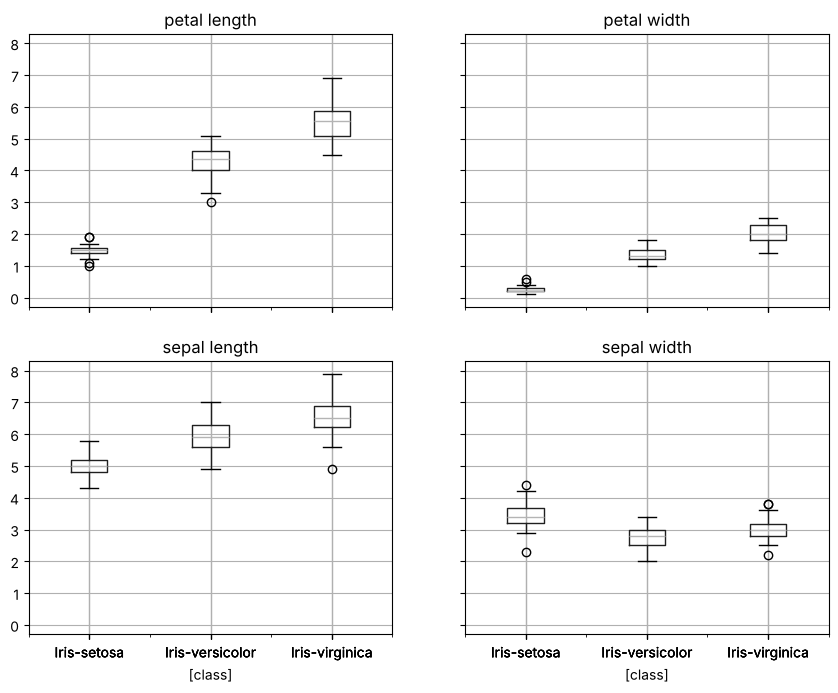

In [13]:
iris.boxplot(by="class", figsize=(10, 8))
plt.suptitle("");

In [14]:
iris.groupby("class").median()

,sepal length,sepal width,petal length,petal width
class,,,,
Iris-setosa,5.0,3.4,1.50,0.2
Iris-versicolor,5.9,2.8,4.35,1.3
Iris-virginica,6.5,3.0,5.55,2.0


**Question.** Which features separate the classes best? Which class is easiest to recognize?

**Answer.** Petal length and petal width: the boxes of *setosa* do not even overlap with the other two classes.
*Setosa* is the easiest class; *versicolor* and *virginica* overlap partially. Sepal width separates the classes least.

### Pair plot

The [`pairplot`](https://seaborn.pydata.org/generated/seaborn.pairplot.html) of the *seaborn* library shows a scatter plot
for every pair of numeric features, and the distribution of each feature on the diagonal.
Use the target as colour (`hue`), set `height=2` and `diag_kind="kde"`.

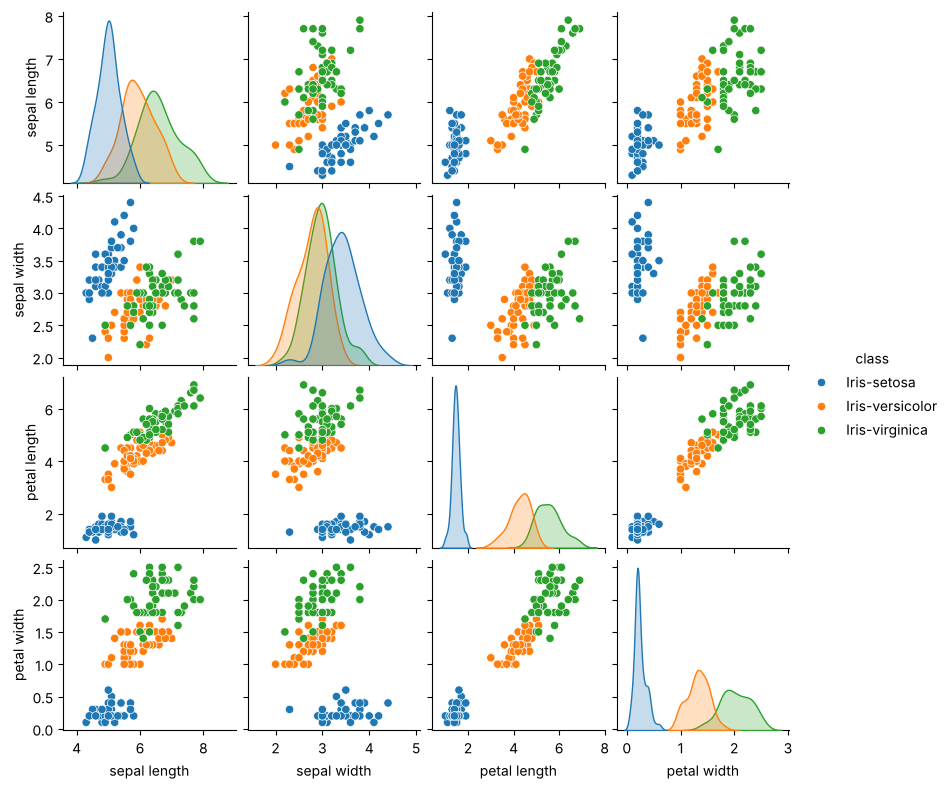

In [15]:
sns.pairplot(data=iris, hue="class", height=2, diag_kind="kde");

### Correlation matrix

Compute the Pearson correlation matrix of the numeric features (`corr(numeric_only=True)`),
then the Spearman one (`method="spearman"`). Show it as a heat map with `sns.heatmap(..., annot=True, vmin=-1, vmax=1, cmap="coolwarm")`.

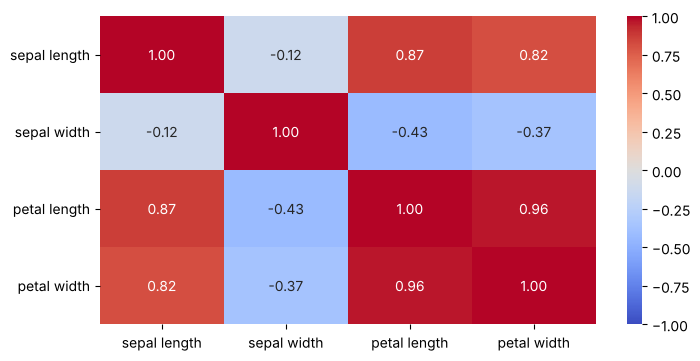

In [16]:
corr = iris.corr(numeric_only=True)
sns.heatmap(corr, annot=True, fmt=".2f", vmin=-1, vmax=1, cmap="coolwarm");

In [17]:
iris.corr(numeric_only=True, method="spearman")

,sepal length,sepal width,petal length,petal width
sepal length,1.00,-0.17,0.88,0.83
sepal width,-0.17,1.00,-0.31,-0.29
petal length,0.88,-0.31,1.00,0.94
petal width,0.83,-0.29,0.94,1.00


### A confounder in Iris ★

Compute the correlation between `sepal length` and `sepal width` on **all** flowers, then **within each class**.
Compare with the scatter plot of the two features in the pair plot. What is happening?

In [18]:
print(f"all flowers: {iris['sepal length'].corr(iris['sepal width']):.2f}")
for c, g in iris.groupby("class"):
    print(f"{c:16s} {g['sepal length'].corr(g['sepal width']):.2f}")

all flowers: -0.12
Iris-setosa      0.74
Iris-versicolor  0.53
Iris-virginica   0.46


**Answer.** On all flowers the correlation is slightly **negative** (about −0.1); within each species it is clearly **positive**
(about 0.45–0.75): within a species, longer sepals are also wider. The species is a confounder:
*setosa* has short but wide sepals, the other two long but narrower ones, and mixing the groups reverses the trend.
Always look within groups before trusting a correlation.

## A6. Findings

Complete the EDA log for Iris (double-click the cell to edit it).

| Finding | Evidence | Decision | Status |
|---|---|---|---|
| 4 ratio features (cm), 1 nominal target, no identifier | `info()` | none | done |
| no missing or impossible values | `isna().sum()`, `describe()` | none | done |
| duplicated rows | `duplicated()` | keep: plausible with 1 mm rounding | noted |
| classes balanced, 50 each | `value_counts()` | accuracy is meaningful here | noted |
| petal features separate the classes; setosa is separable | box plots by class, pair plot | hypothesis for the model | **open** |
| sepal length vs width: negative overall, positive within class | correlation per class | species is a confounder | noted |

# Part B — NordicMart customers

The customer table used in Lecture 6: 3000 customers of the NordicMart retail chain, synthetic but realistic,
with the target **churned** (1 = the customer stopped buying). The file is `nordicmart_customers.csv` in your data folder.
Several numbers you compute here appear on the lecture slides: check them.

## B1. Kind of data set and type of every column

Load the file into `df` (the **raw** table: it will not be modified), then show `shape`, `head()` and `info()`.

In [19]:
df = pd.read_csv(NORDICMART_FILE)
print(df.shape)
df.head()

(3000, 9)


,customer_id,tier,age,days_since_last_buy,annual_spend,web_sessions_month,tickets_90d,postcode,churned
0,C-0000,Silver,58.0,27.0,681.03,NaN,0,40100.0,0
1,C-0001,Basic,34.0,95.0,91.08,NaN,0,40100.0,1
2,C-0002,Gold,18.0,37.0,978.61,NaN,0,NaN,0
3,C-0003,Silver,21.0,15.0,973.64,2.0,1,40100.0,0
4,C-0004,Basic,62.0,44.0,213.12,NaN,0,40100.0,0


In [20]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 3000 entries, 0 to 2999
Data columns (total 9 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   customer_id          3000 non-null   str    
 1   tier                 3000 non-null   str    
 2   age                  2697 non-null   float64
 3   days_since_last_buy  3000 non-null   float64
 4   annual_spend         3000 non-null   float64
 5   web_sessions_month   2460 non-null   float64
 6   tickets_90d          3000 non-null   int64  
 7   postcode             2777 non-null   float64
 8   churned              3000 non-null   int64  
dtypes: float64(5), int64(2), str(2)
memory usage: 211.1 KB


Count the distinct values of every column with `nunique()`.

**Question.** For every column give the type (identifier, nominal, ordinal, interval, ratio, count, binary target).
Look carefully at `postcode`: which type did pandas give it, and is it right? How many distinct values does it have?

In [21]:
df.nunique()

customer_id            3000
tier                      3
age                      67
days_since_last_buy     247
annual_spend           2959
web_sessions_month       16
tickets_90d               7
postcode                  1
churned                   2
dtype: int64

**Answer.**

| Column | Type | Note |
|---|---|---|
| customer_id | identifier | unique per row: **not a feature** |
| tier | ordinal (Basic < Silver < Gold) | read as text: the order must be set by us |
| age | ratio, continuous | |
| days_since_last_buy | ratio, continuous | |
| annual_spend | ratio, continuous | |
| web_sessions_month | count (ratio, discrete) | |
| tickets_90d | count (ratio, discrete) | |
| postcode | **nominal** | read as `float64` because of the missing values; and it has a **single** value: a constant column carries no information |
| churned | binary target | |

Create the **working copy** `customers` on which every fix will be applied, and in it:

1. store `postcode` as text (`astype("string")`, after removing the decimal part) — or simply drop it, since it is constant;
1. make `tier` an *ordered categorical*, so that sorting and plots keep Basic < Silver < Gold:
   `pd.Categorical(..., categories=[...], ordered=True)`.

Keep `customer_id` in the copy for reference, but remember that it is not a feature.

In [22]:
customers = df.copy()
customers = customers.drop(columns="postcode")     # constant column (one value + missing)
customers["tier"] = pd.Categorical(customers["tier"], categories=["Basic", "Silver", "Gold"], ordered=True)
customers.dtypes

customer_id                 str
tier                   category
age                     float64
days_since_last_buy     float64
annual_spend            float64
web_sessions_month      float64
tickets_90d               int64
churned                   int64
dtype: object

## B2. Summaries and one plot per variable

### Summary statistics

Show `describe()` of `annual_spend` and compute the IQR. Is the distribution symmetric?

In [23]:
spend = customers["annual_spend"]
print(spend.describe())
print("IQR:", spend.quantile(0.75) - spend.quantile(0.25))

count    3000.00
mean      775.38
std       656.09
min        48.51
25%       358.08
50%       569.12
75%       952.14
max      6181.21
Name: annual_spend, dtype: float64
IQR: 594.0625


**Answer.** Mean 775 > median 569: a few large values pull the mean up — **right skew**. IQR ≈ 594.

### Robust vs non-robust ★

On a **copy** of the spend column, multiply the largest value by 10 (a misplaced decimal point)
and compare mean, std, median and IQR before and after.

In [24]:
wrong = spend.copy()
wrong[wrong.idxmax()] *= 10
def summary(s):
    return pd.Series({"max": s.max(), "mean": s.mean(), "std": s.std(), "median": s.median(),
                      "IQR": s.quantile(0.75) - s.quantile(0.25)})
pd.DataFrame({"original": summary(spend), "max x 10": summary(wrong)}).round(0)

,original,max x 10
max,6181.0,61812.0
mean,775.0,794.0
std,656.0,1289.0
median,569.0,569.0
IQR,594.0,594.0


**Answer.** One value out of 3000: the std almost doubles, the mean moves by about 2%, median and IQR do not change at all.

### Histograms and the bin width

Draw the histogram of `annual_spend` with 8 bins, with 80 bins, and with the Freedman–Diaconis rule (`bins="fd"`).
Then draw it with a logarithmic x axis: use `np.log10(spend)` as data.

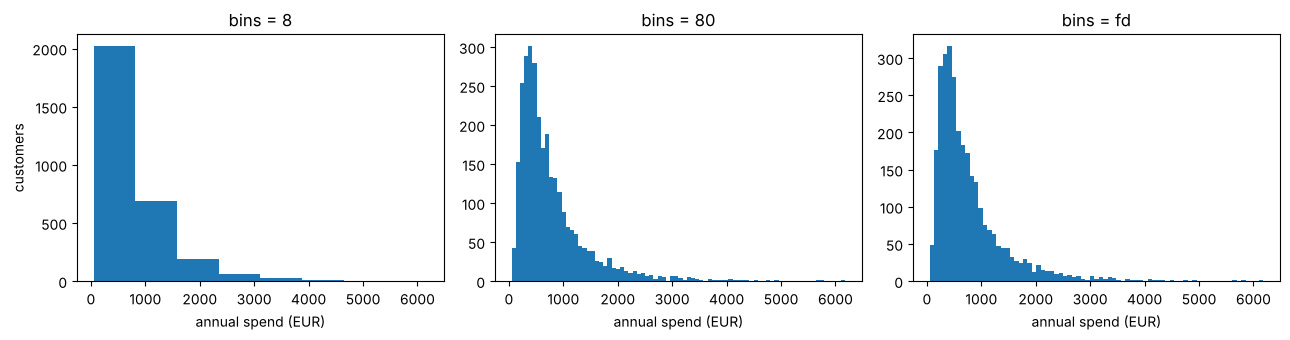

In [25]:
fig, axs = plt.subplots(1, 3, figsize=(13, 3.5))
for ax, b in zip(axs, [8, 80, "fd"]):
    ax.hist(spend, bins=b)
    ax.set_title(f"bins = {b}")
    ax.set_xlabel("annual spend (EUR)")
axs[0].set_ylabel("customers")
plt.tight_layout()

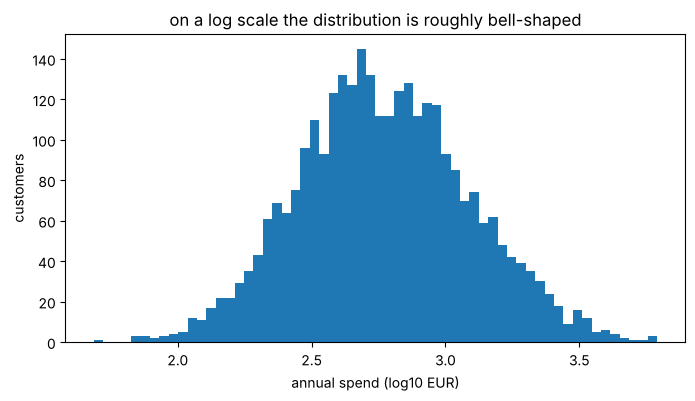

In [26]:
fig, ax = plt.subplots()
ax.hist(np.log10(spend), bins=60)
ax.set_xlabel("annual spend (log10 EUR)")
ax.set_ylabel("customers")
ax.set_title("on a log scale the distribution is roughly bell-shaped");

### One plot per variable

Draw a histogram of every numeric column (`customers.hist(...)`), and a bar chart of the counts of `tier`
**in the natural order** (`value_counts(sort=False)` on the ordered categorical, then `.plot.bar()`).

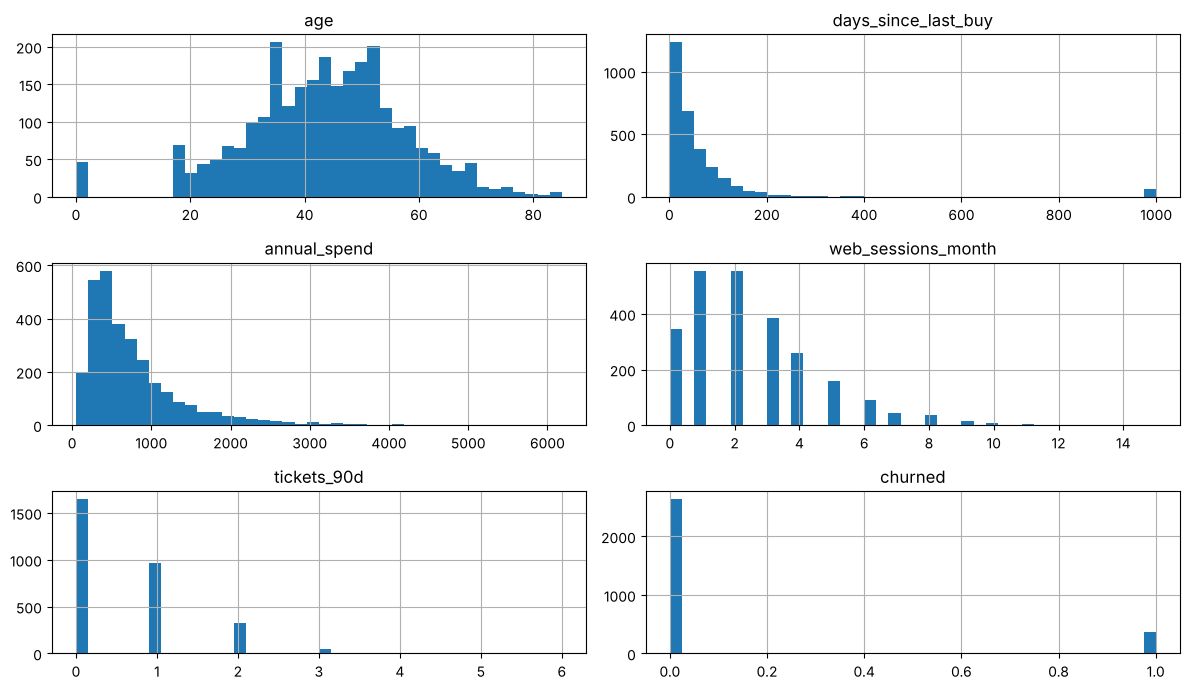

In [27]:
customers.hist(figsize=(12, 7), bins=40);
plt.tight_layout()

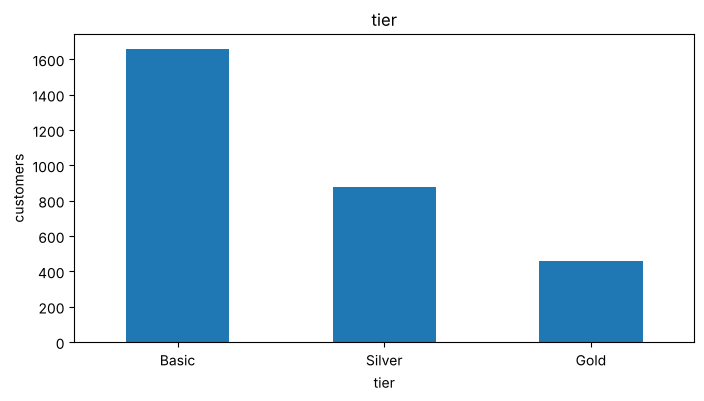

In [28]:
customers["tier"].value_counts(sort=False).plot.bar(rot=0, ylabel="customers", title="tier");

**Question.** Look at the histograms: which columns are skewed? Which ones show something strange?

**Answer.** `annual_spend` and `days_since_last_buy` are right-skewed; `tickets_90d` and `web_sessions_month` are small counts.
Two strange things: `days_since_last_buy` has an isolated group of values far to the right (around 1000),
and `age` has a group of values at 0. Both are investigated in B3.

## B3. Data quality

### Codes and defaults that look like numbers

1. Show the most frequent values of `days_since_last_buy` and its maximum. What is 999?
1. How many customers have `age == 0`?
1. In `customers`, recode both as missing (`replace(999, np.nan)`, `replace(0, np.nan)`), **and** keep a flag column
   `never_bought` (1 if the recency was 999).
1. Compare the mean and the median of the recency before and after the recoding.

In [29]:
rec = df["days_since_last_buy"]
print(rec.value_counts().head(5))
print("max:", rec.max(), "| rows with 999:", (rec == 999).sum())
print("age == 0:", (df["age"] == 0).sum())

days_since_last_buy
10.0     71
4.0      66
3.0      64
7.0      61
999.0    61
Name: count, dtype: int64
max: 999.0 | rows with 999: 61
age == 0: 47


In [30]:
customers["never_bought"] = (customers["days_since_last_buy"] == 999).astype(int)
customers["days_since_last_buy"] = customers["days_since_last_buy"].replace(999, np.nan)
customers["age"] = customers["age"].replace(0, np.nan)

pd.DataFrame({"codes in": [rec.mean(), rec.median()],
              "codes out": [customers["days_since_last_buy"].mean(), customers["days_since_last_buy"].median()]},
             index=["mean", "median"]).round(1)

,codes in,codes out
mean,69.5,50.2
median,34.0,33.0


**Answer.** 999 is the most frequent single value and the maximum: a code meaning "never bought", not a number of days.
61 rows (2%) move the mean recency from about 70 to 50 days; the median barely moves (34 → 33).
47 customers have age 0: the default value typed at the till. Both are missing values in disguise.

### Missing values: how many, and why?

1. Compute the percentage of missing values per column in `customers` (`isna().mean()`), and draw it as a horizontal bar chart.
1. Is missingness **informative**? Compare the churn rate of customers with and without `web_sessions_month`,
   and with and without `age`: `customers.groupby(customers["web_sessions_month"].isna())["churned"].mean()`.

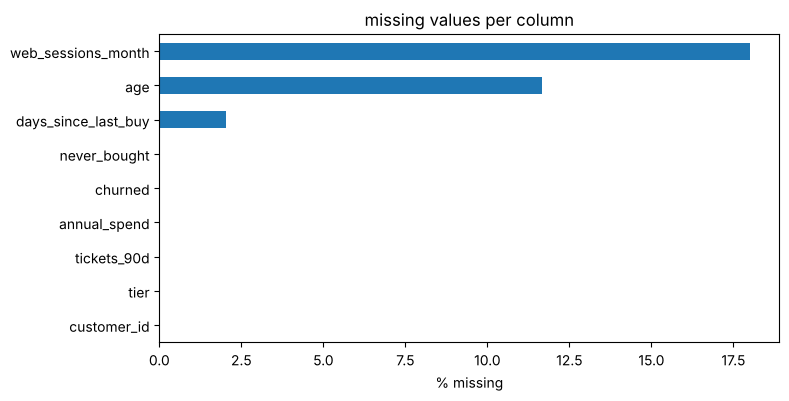

In [31]:
missing = customers.isna().mean().mul(100).sort_values()
missing.plot.barh(xlabel="% missing", title="missing values per column");

In [32]:
for col in ["web_sessions_month", "age"]:
    rates = customers.groupby(customers[col].isna())["churned"].mean().rename({False: "recorded", True: "missing"})
    print(col, (rates * 100).round(1).to_dict())

web_sessions_month {'recorded': 9.6, 'missing': 23.1}
age {'recorded': 11.9, 'missing': 12.6}


**Answer.** About 18% of web sessions, 11% of ages (10% plus the recoded zeros) and 2% of recency values are missing.
Customers **without** web sessions churn at about 23% against 10%: they are store-only customers, and the missingness
is itself a signal (*not at random*): filling it with the average would erase it — keep a "missing" indicator.
For age the churn rate is the same with and without the value: compatible with *completely at random*.

### Outliers: the IQR rule

1. Compute the fences Q1 − 1.5·IQR and Q3 + 1.5·IQR of `annual_spend` and count the customers beyond them.
1. Count the same candidate outliers per tier, and draw a box plot of spend by tier (`customers.boxplot(column=..., by=...)`).
1. Are they errors?

In [33]:
q1, q3 = spend.quantile([0.25, 0.75])
iqr = q3 - q1
low, high = q1 - 1.5 * iqr, q3 + 1.5 * iqr
out = customers[(spend < low) | (spend > high)]
print(f"fences: {low:.0f} .. {high:.0f} EUR | candidate outliers: {len(out)}")
out["tier"].value_counts(sort=False)

fences: -533 .. 1843 EUR | candidate outliers: 204


tier
Basic      10
Silver     63
Gold      131
Name: count, dtype: int64

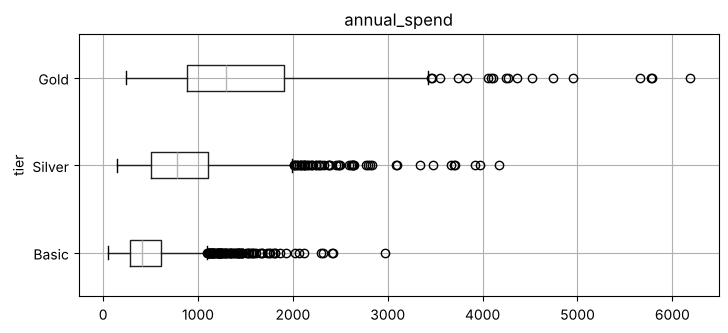

In [34]:
customers.boxplot(column="annual_spend", by="tier", vert=False, figsize=(8, 3.5))
plt.suptitle("");   # removes the automatic "grouped by" title

**Answer.** The upper fence is about 1843 EUR, with 204 candidate outliers (the lower fence is negative).
They are mostly Gold customers, who spend more: within their own tier they are ordinary.
Rare but real customers, not errors: **keep** them, and consider a log transform for methods sensitive to large values.

### Duplicates

Is `customer_id` unique? Are there duplicated rows?

In [35]:
print("duplicated ids:", df["customer_id"].duplicated().sum())
print("duplicated rows (ignoring the id):", df.drop(columns="customer_id").duplicated().sum())

duplicated ids: 0
duplicated rows (ignoring the id): 0


**Answer.** No duplicated identifiers and no duplicated rows: nothing to fix. "Nothing found" is a finding too: write it down.

## B4. The target: class imbalance

1. Show the counts and the shares of `churned` (`value_counts(normalize=True)`).
1. The trivial model predicts "stays" (0) for every customer. Show its confusion table with
   `pd.crosstab(actual, predicted)` and compute its accuracy and the number of churners it finds.

In [36]:
print(customers["churned"].value_counts())
print(customers["churned"].value_counts(normalize=True).round(3))

churned
0    2640
1     360
Name: count, dtype: int64
churned
0    0.88
1    0.12
Name: proportion, dtype: float64


In [37]:
actual = customers["churned"].rename("actual")
predicted = pd.Series(0, index=customers.index, name="predicted")
print(pd.crosstab(actual, predicted))
print(f"accuracy: {(actual == predicted).mean():.0%} | churners found: {((actual == 1) & (predicted == 1)).sum()}")

predicted     0
actual         
0          2640
1           360
accuracy: 88% | churners found: 0


**Answer.** Only 12% churned (360 of 3000). The trivial model is 88% accurate and finds 0 churners:
with an imbalanced target, accuracy alone is misleading, and 88% is the floor any real model must beat.

## B5. Each feature × target; correlations; confounders

### Numeric × numeric: scatter plot coloured by the target

Scatter plot of `days_since_last_buy` (x) against `annual_spend` (y, log scale), coloured by `churned`.
Against overplotting use small markers and transparency (`alpha`).

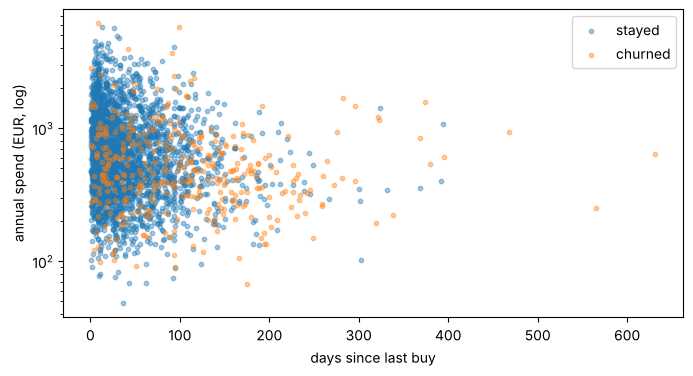

In [38]:
fig, ax = plt.subplots()
for value, label in [(0, "stayed"), (1, "churned")]:
    s = customers[customers["churned"] == value]
    ax.scatter(s["days_since_last_buy"], s["annual_spend"], s=10, alpha=0.4, label=label)
ax.set_yscale("log")
ax.set_xlabel("days since last buy")
ax.set_ylabel("annual spend (EUR, log)")
ax.legend();

### Numeric feature × target: box plots per class

Box plots of `days_since_last_buy` and of `tickets_90d`, grouped by `churned`. Which one looks like a promising feature?

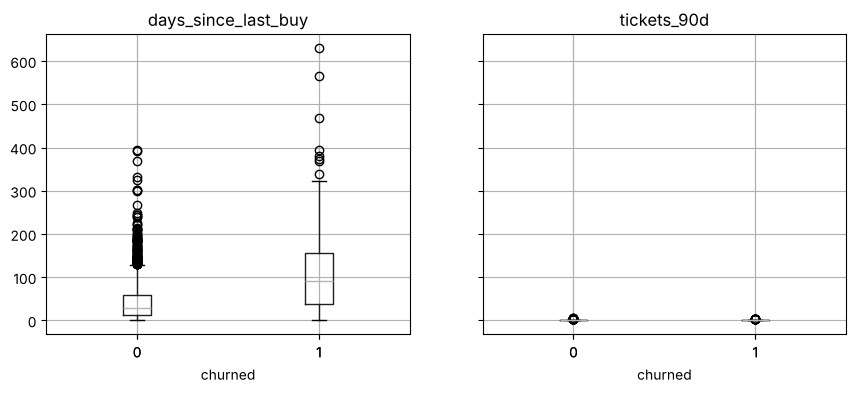

In [39]:
customers.boxplot(column=["days_since_last_buy", "tickets_90d"], by="churned", figsize=(10, 4))
plt.suptitle("");

**Answer.** Recency: churners have clearly higher values at every spend level — a promising feature (a *hypothesis*
for the model). Tickets: the boxes overlap almost completely, a weak signal at best. Spend alone separates little.

### Categorical feature × target: rates and the cross-table

1. Churn rate per tier (`groupby(...)["churned"].mean()`), as a bar chart with the overall rate as a reference line (`ax.axhline`).
1. The cross-table tier × churned with totals: `pd.crosstab(..., margins=True)`.

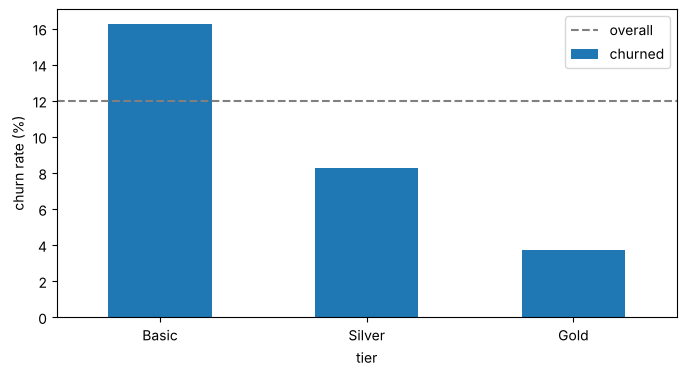

In [40]:
rate = customers.groupby("tier", observed=True)["churned"].mean() * 100
ax = rate.plot.bar(rot=0, ylabel="churn rate (%)")
ax.axhline(customers["churned"].mean() * 100, color="gray", ls="--", label="overall")
ax.legend();

In [41]:
pd.crosstab(customers["tier"], customers["churned"], margins=True)

churned,0,1,All
tier,,,
Basic,1390,270,1660
Silver,807,73,880
Gold,443,17,460
All,2640,360,3000


**Answer.** Churn falls from 16% (Basic) to 8% (Silver) and 4% (Gold), against 12% overall.
Basic holds three quarters of the churners, but also more than half of the customers: compare rates, not counts.
Gold has only 17 churners: its rate is the least stable.

### Correlation matrix

Pearson correlation matrix of the numeric columns of `customers` (without `customer_id`), as an annotated heat map.
Then compute the Spearman matrix: which pairs change most? Why?

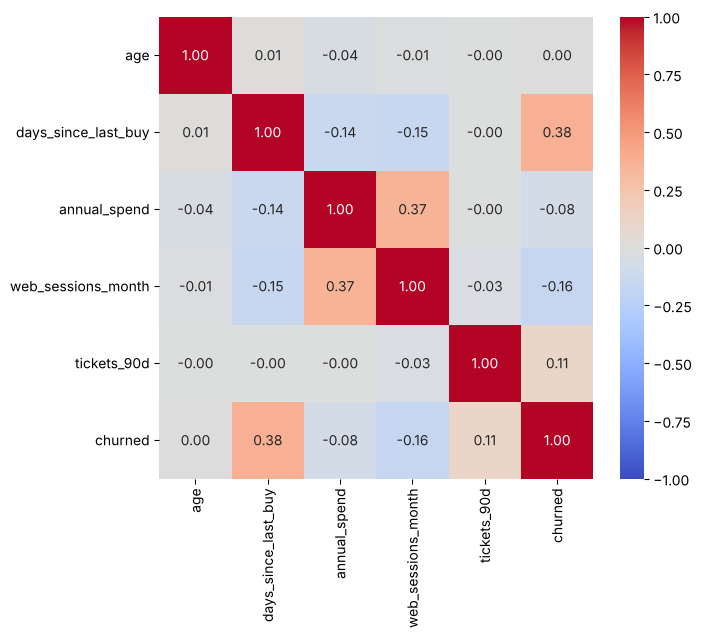

In [42]:
num = customers.drop(columns=["customer_id", "never_bought"]).select_dtypes("number")
fig, ax = plt.subplots(figsize=(7, 6))
sns.heatmap(num.corr(), annot=True, fmt=".2f", vmin=-1, vmax=1, cmap="coolwarm", ax=ax);

In [43]:
(num.corr(method="spearman") - num.corr()).round(2)

,age,days_since_last_buy,annual_spend,web_sessions_month,tickets_90d,churned
age,0.00,-0.01,0.02,-0.01,0.01,0.01
days_since_last_buy,-0.01,0.00,-0.00,0.01,-0.01,-0.10
annual_spend,0.02,-0.00,0.00,0.00,-0.02,-0.02
web_sessions_month,-0.01,0.01,0.00,0.00,0.00,-0.01
tickets_90d,0.01,-0.01,-0.02,0.00,0.00,-0.01
churned,0.01,-0.10,-0.02,-0.01,-0.01,0.00


**Answer.** Recency has the strongest correlation with churn (about 0.38); age none.
Spend and web sessions correlate (about 0.37). Here Spearman and Pearson differ by at most about 0.1:
no relation is strongly curved or created by a few extreme values. Where they do differ (recency vs churned),
the cause is the long right tail of recency: ranks are not affected by how far the extreme values are.

### Checking a confounder

Spend and web sessions correlate. Do web sessions *cause* spending? Compute the correlation between `annual_spend`
and `web_sessions_month` on all customers, then **within each tier**.

In [44]:
print(f"all customers: {customers['annual_spend'].corr(customers['web_sessions_month']):.2f}")
for t, g in customers.groupby("tier", observed=True):
    print(f"{t:7s} {g['annual_spend'].corr(g['web_sessions_month']):.2f}")

all customers: 0.37
Basic   0.04
Silver  0.04
Gold    -0.00


**Answer.** About 0.37 on all customers, about 0 within each tier: tier drives both (Gold customers visit more *and*
spend more). Tier is a confounder; pushing customers to the web shop would not, by itself, make them spend more.

### Many variables: the pair plot ★

Pair plot of recency, log spend, web sessions and tickets, coloured by `churned`, on a random sample of 900 customers
(`sample(900, random_state=SEED)`). Add a column with `np.log10` of the spend first.
How many panels would you need for 50 features?

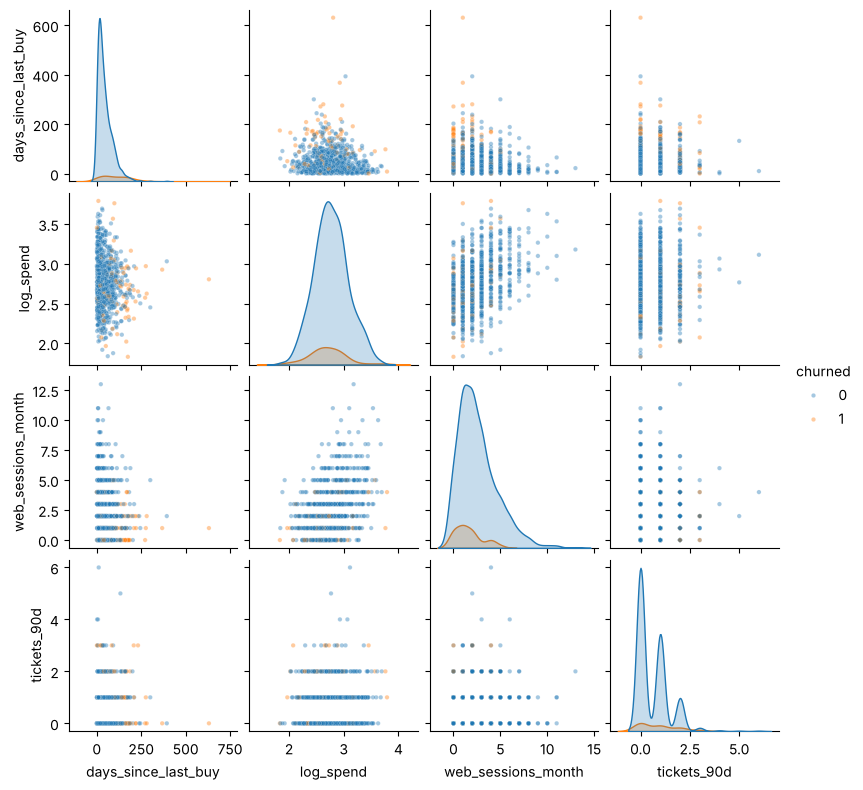

In [45]:
p = customers.dropna(subset=["days_since_last_buy", "web_sessions_month"]).sample(900, random_state=SEED)
p = p.assign(log_spend=np.log10(p["annual_spend"]))
sns.pairplot(p[["days_since_last_buy", "log_spend", "web_sessions_month", "tickets_90d", "churned"]],
             hue="churned", height=2, plot_kws={"s": 10, "alpha": 0.4});

**Answer.** With 4 features: 16 panels. With 50 features: 2500 panels (1225 distinct pairs) — pairwise views do not scale.

## B6. Findings → preparation actions

Complete the EDA log for NordicMart. For each finding: the evidence (which plot, which number), the decision, and the status
(*done* if already applied to `customers`, *noted*, or *open* if only the model can answer).

| Finding | Evidence | Decision | Status |
|---|---|---|---|
| `customer_id` is an identifier | `nunique()` = 3000 | drop before modeling | noted |
| `postcode` constant (one value + missing) | `nunique()` = 1 | dropped | done |
| `tier` is ordinal | domain | ordered categorical; encode keeping the order | done |
| recency 999 = "never bought" | value counts, histogram spike; 61 rows | recode missing + flag `never_bought` | done |
| age 0 = default at the till | histogram; 47 rows | recode missing | done |
| sessions missing = store-only | 18% missing; churn 23% vs 10% | keep a "missing" indicator; do not fill with the mean | noted |
| age missing at random | churn rate equal with/without age | simple imputation is acceptable | noted |
| spend right-skewed; 204 candidate outliers, mostly Gold | describe, histograms, IQR fences | keep; consider log transform | noted |
| no duplicates | `duplicated()` | none | done |
| churned only 12% | `value_counts()`; trivial model 88% | do not judge models by accuracy alone | noted |
| spend ↔ sessions 0.37, ≈ 0 within tier | correlation per tier | confounded by tier: not a lever | noted |
| recency separates churners | scatter, box plots, r ≈ 0.38 | hypothesis for the model | **open** |

## Before you close

1. **Kernel → Restart & Run All**: the notebook must run from top to bottom without errors.
1. Check that the raw tables `iris` and `df` were never modified: every fix is in `customers`.
1. Save. Keep this notebook: the working copy `customers` and your EDA log are the starting point of the next labs.

In [46]:
# quick self-check: the raw table is untouched
assert (df["days_since_last_buy"] == 999).sum() == 61, "the raw table was modified!"
print("raw table untouched")

raw table untouched
